# Monthly scorecard refresh

This notebook runs the whole monthly reporting cycle in one go and shows the results:

1. load the raw Olist files into SQL
2. run the **data-quality checks**
3. build the clean reporting tables
4. run the scorecard queries
5. refresh the **Excel scorecard** and the **dashboard** images

Next month, an analyst drops in the new raw files and runs this notebook. Nothing is copied or pasted by hand.

*Data: Olist Brazilian e-commerce marketplace (public, anonymized), Jan 2017 - Aug 2018. Amounts in R$.*

In [1]:
import sys
import pandas as pd
sys.path.append("../python")
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:,.2f}".format)

import refresh_report

results = refresh_report.main()
print(f"Refreshed {len(results)} reports:", ", ".join(results))

Refreshed 11 reports: data_quality_checks, monthly_scorecard, payment_methods, card_installments, seller_funnel_by_channel, seller_activation_by_type, seller_concentration, delivery_vs_review, late_delivery_cause, category_performance, delivery_by_state


## 1. Data-quality checks
These run before anything is reported. Each issue is fixed in `sql/02_clean_tables.sql` or kept out of the metric it would distort.

In [2]:
results["data_quality_checks"]

,check_name,failing_rows,action
0,Orders in partial months (outside Jan 2017 - Aug 2018),349,Excluded from monthly trends
1,Orders with no items,775,Excluded from sales metrics (mostly canceled)
2,Orders with no payment record,1,Excluded from payment metrics
3,Amount paid differs from items + freight,249,"Kept; sales use item prices, payments use amount paid"
4,"Payment rows: undefined type, R$0 or 0 installments",11,Excluded from payment-method metrics
5,Extra review rows for the same order,551,Keep the latest review per order
6,Delivered orders missing delivery date,8,Excluded from delivery metrics
7,Handed to carrier before payment approved,1359,Kept; timestamps come from different systems
8,Products with no category,610,"Reported as ""unknown"""
9,Categories missing an English name,2,Translated in the clean table


## 2. Leadership scorecard: latest month vs prior month

In [3]:
sc = results["monthly_scorecard"].set_index("month")
latest, prior = sc.index[-1], sc.index[-2]
kpis = ["gmv", "orders", "avg_order_value", "active_sellers", "new_sellers", "gmv_per_active_seller",
        "credit_card_share_pct", "delivered_on_time_pct", "avg_review_score"]
summary = sc.loc[[prior, latest], kpis].T
summary["change_%"] = ((summary[latest] / summary[prior] - 1) * 100).round(1)
summary

month,2018-07,2018-08,change_%
gmv,"878,044.00","848,860.00",-3.30
orders,"6,292.00","6,512.00",3.50
avg_order_value,140.87,132.20,-6.20
active_sellers,"1,245.00","1,266.00",1.70
new_sellers,190.00,155.00,-18.40
gmv_per_active_seller,705.00,671.00,-4.80
credit_card_share_pct,75.50,79.40,5.20
delivered_on_time_pct,96.60,93.80,-2.90
avg_review_score,4.26,4.26,0.00


## 3. Payments: methods and card installment plans

In [4]:
results["payment_methods"]

,payment_method,orders,order_share_pct,value_share_pct,avg_amount_paid,median_hours_to_approve,canceled_pct,avg_review_score
0,credit_card,73889,75.50,78.50,166.59,0.30,1.11,4.09
1,boleto,19479,19.90,18.00,144.65,29.10,1.23,4.09
2,voucher,3028,3.10,2.20,114.93,0.30,3.04,4.02
3,debit_card,1512,1.50,1.40,140.29,0.80,0.85,4.17


In [5]:
results["card_installments"]

,installment_plan,orders,order_share_pct,value_share_pct,avg_amount_paid
0,1) Paid in full,23676,32.00,19.40,100.83
1,2) 2-3 installments,22345,30.20,24.60,135.32
2,3) 4-6 installments,15920,21.50,23.60,182.19
3,4) 7-10 installments,11612,15.70,31.50,333.80
4,5) 11+ installments,336,0.50,1.00,362.25


## 4. Seller onboarding: from marketing lead to first sale

In [6]:
results["seller_funnel_by_channel"]

,lead_channel,leads,signed_sellers,lead_to_signed_pct,median_days_to_close,signed_with_first_sale_pct,gmv_per_signed_seller
0,organic_search,2296,271,11.80,14.50,48.50,764.00
1,paid_search,1586,195,12.30,15.00,59.60,784.00
2,social,1350,75,5.60,30.00,47.60,579.00
3,unknown,1159,193,16.70,11.00,47.40,"1,113.00"
4,direct_traffic,499,56,11.20,10.00,58.50,391.00
5,email,493,15,3.00,21.00,46.20,566.00
6,referral,284,24,8.50,18.50,47.40,745.00
7,other,150,4,2.70,9.00,50.00,"1,722.00"
8,display,118,6,5.10,8.50,33.30,154.00
9,other_publicities,65,3,4.60,35.00,0.00,0.00


In [7]:
results["seller_activation_by_type"]

,seller_type,signed_sellers,with_first_sale_pct,avg_days_to_first_sale,gmv_per_signed_seller
0,online_medium,286,58.40,57.00,704.00
1,online_big,108,69.40,45.00,"2,680.00"
2,industry,107,35.50,54.00,263.00
3,offline,90,33.30,67.00,216.00
4,online_small,65,43.10,51.00,807.00
5,online_beginner,47,44.70,43.00,475.00
6,online_top,14,42.90,27.00,585.00


## 5. Service: delivery and customer reviews

In [8]:
results["delivery_vs_review"]

,delivery,orders,share_pct,avg_review_score,low_review_pct
0,1) On time,89672,93.20,4.29,9.20
1,2) 1-3 days late,1869,1.90,3.29,32.10
2,3) 4-7 days late,1802,1.90,2.10,67.70
3,4) 8+ days late,2860,3.00,1.70,79.30


In [9]:
results["late_delivery_cause"]

,seller_handoff,delivered_orders,late_delivery_pct,avg_review_score
0,Seller shipped on time,87610,5.40,4.20
1,Seller shipped late,8592,21.10,3.70


## 6. Dashboard

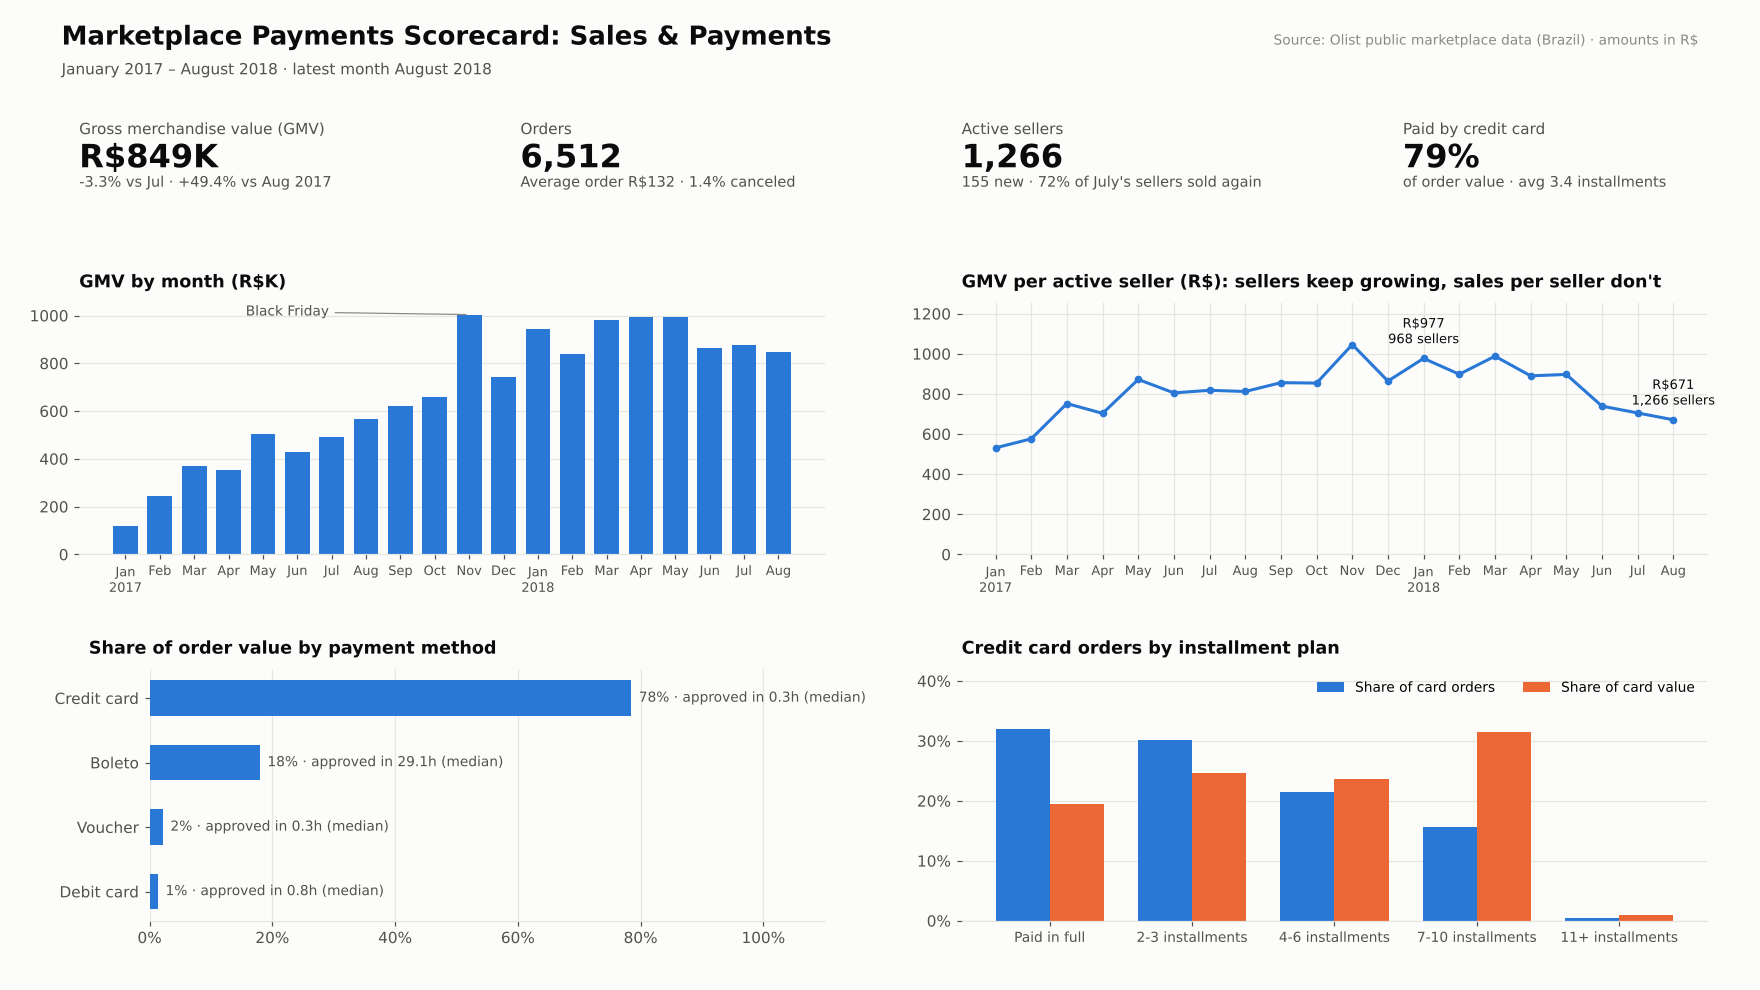

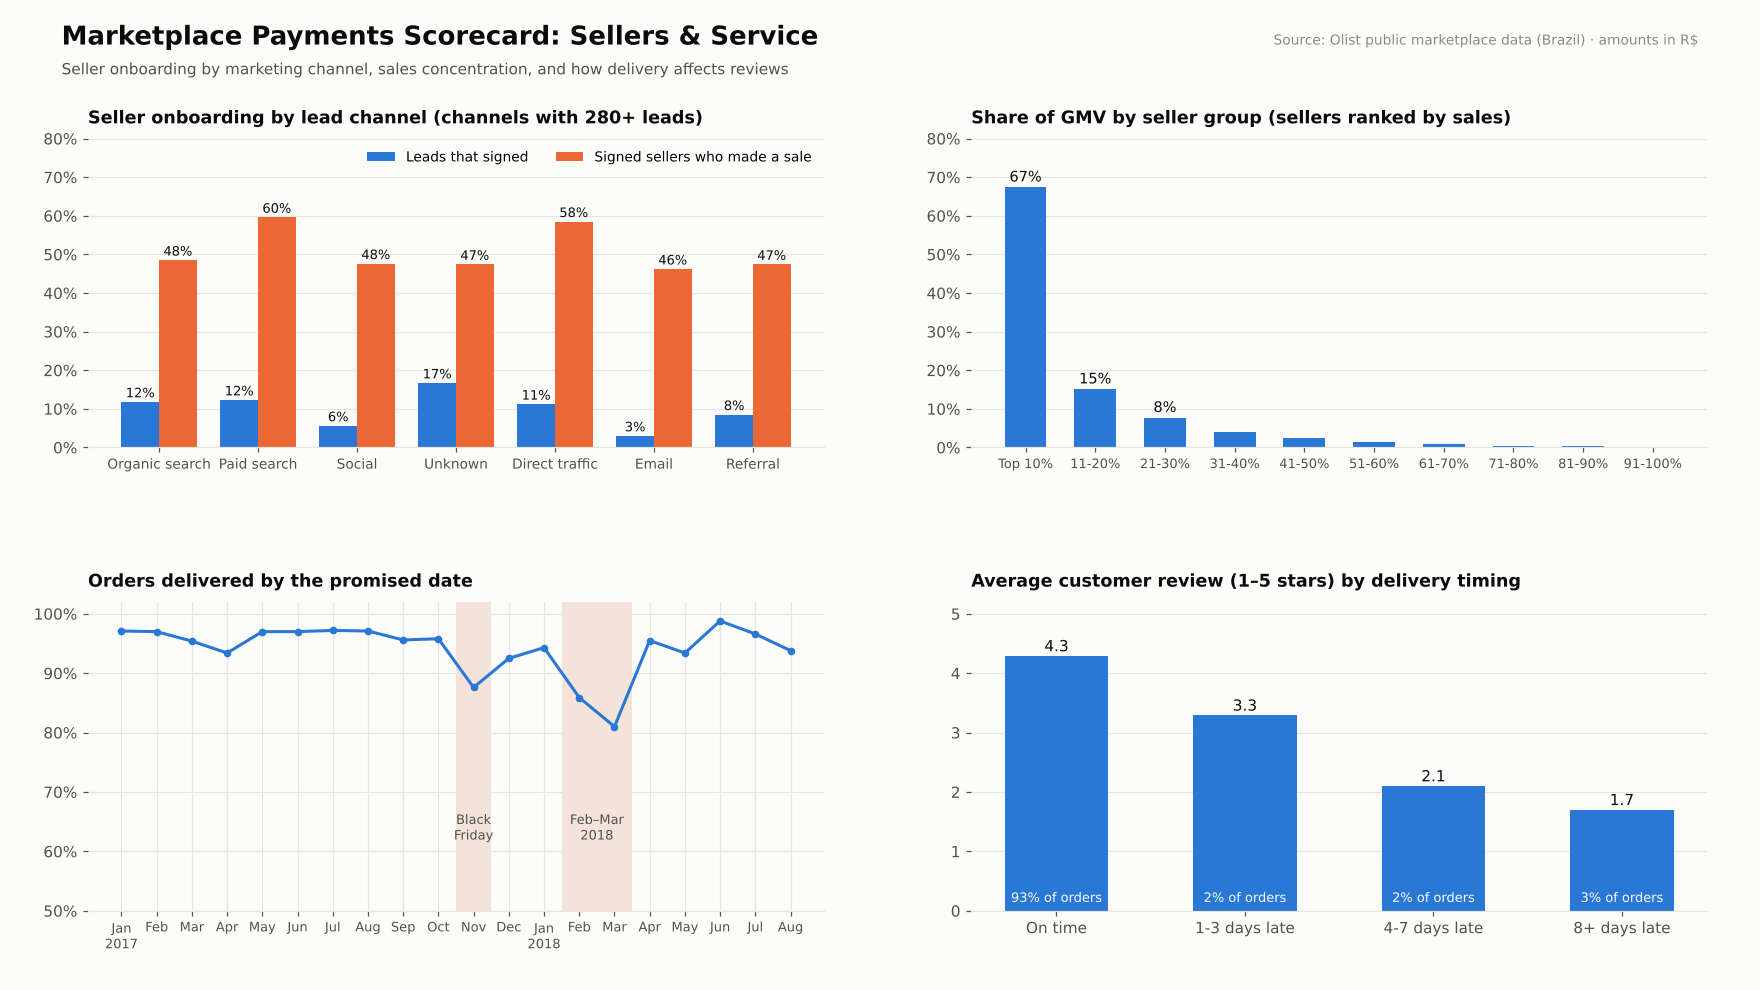

In [10]:
from IPython.display import Image, display
display(Image("../dashboard/page1_sales_and_payments.png"))
display(Image("../dashboard/page2_sellers_and_service.png"))